In [ ]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm, to_rgb
from matplotlib.lines import Line2D
from scipy.stats import t as t_dist
from joblib import Parallel, delayed

In [2]:
# ---- Table 1 ----
F = 0.10          # f: input strength
S = 0.0005        # s: stimulus (semantic feature) -> response (lexical item) weight
D = 0.05          # d: decay
SIGMA_A = 0.20    # a: SD of the activation-based (multiplicative) noise
SIGMA_I = 0.0009  # i: SD of the intrinsic (additive) noise
K = 5             # k: selection threshold on conflict
R = 110           # r: ms per time step (RT conversion)
ETA = 0.01        # eta: Hebbian learning rate

RT_MAX = 10000    # trial cap (ms)

# ---- network layout ----
N_CAT, N_ITEM = 5, 5          # categories, items per category
N_SHARED, N_UNIQUE = 3, 7     # features per item: shared within category / unique
FEAT_PER_CAT = N_SHARED + N_ITEM * N_UNIQUE          # 38
N_STIM = N_CAT * FEAT_PER_CAT                         # 190 stimulus nodes
N_RESP = N_CAT * N_ITEM                               # 25 response nodes
STIM = slice(0, N_STIM)
RESP = slice(N_STIM, N_STIM + N_RESP)
N_NODES = N_STIM + N_RESP                             # 215

In [3]:
def init_w(s=S, d=D):
    """Weight matrix (row = sender, column = receiver), 215 x 215."""
    w_cat = np.zeros((FEAT_PER_CAT, N_ITEM))
    w_cat[:N_SHARED, :] = s                                   # shared features -> every item
    for m in range(N_ITEM):
        start = N_SHARED + m * N_UNIQUE
        w_cat[start:start + N_UNIQUE, m] = s                  # unique features -> own item
    w_sr = np.kron(np.eye(N_CAT), w_cat)                      # 190 x 25 stimulus -> response
    top = np.hstack(((1 - d) * np.eye(N_STIM), w_sr))
    bottom = np.hstack((w_sr.T, (1 - d) * np.eye(N_RESP)))    # symmetric feedback
    return np.vstack((top, bottom))


def item_features(cat, item):
    """Indices of the 10 stimulus nodes of item `item` (0-4) in category `cat` (0-4)."""
    base = cat * FEAT_PER_CAT
    shared = np.arange(base, base + N_SHARED)
    unique = np.arange(base + N_SHARED + item * N_UNIQUE, base + N_SHARED + (item + 1) * N_UNIQUE)
    return np.concatenate([shared, unique])


def item_index(cat, item):
    """Response-layer index (0-24) of an item."""
    return cat * N_ITEM + item


def make_input(cat, item, f=F):
    """Clamped input fX for naming one picture."""
    x = np.zeros(N_NODES)
    x[item_features(cat, item)] = f
    return x


def add_noise(a_t, sigma_a=SIGMA_A, sigma_i=SIGMA_I):
    """A(t) * N(0, a) + N(0, i)  (Equation 1), based on the activation at time t."""
    n = len(a_t)
    return np.random.normal(scale=sigma_a, size=n) * np.abs(a_t) + np.random.normal(scale=sigma_i, size=n)


def update_activation(x, a_t, w):
    """Equation 1: A(t+1) = (A(t) + fX) W + noise, negative values set to 0."""
    a_next = (a_t + x) @ w + add_noise(a_t)
    a_next[a_next < 0] = 0
    return a_next


def conflict(a):
    """Equation 2 on the response layer."""
    r = np.sort(a[RESP])[-2:]
    return np.log(1 / (r[1] - r[0] + 1e-10))


def run_trial(x, w, k=K):
    """One naming trial. Returns the activation at selection, the selected item (0-24) and RT (ms)."""
    a = x.copy()
    rt, c = 0, np.inf
    while c > k and rt < RT_MAX:
        a = update_activation(x, a, w)
        c = conflict(a)
        rt += R
    return a, int(np.argmax(a[RESP])), rt


def hebbian_update(w, a, eta=ETA):
    """Equation 3: dw_ij = eta * A_i * A_j for every stimulus node i and response node j (symmetric)."""
    dw = eta * np.outer(a[STIM], a[RESP])
    w[STIM, RESP] += dw
    w[RESP, STIM] += dw.T
    return w

In [4]:
FILLER = (1, 0)
FILLER_FEATS = item_features(*FILLER)
FILLER_RESP = N_STIM + item_index(*FILLER)


def cn_sequence(lag):
    """List of (category, item, ordinal_position); fillers have ordinal_position 0."""
    seq = []
    for pos in range(1, N_ITEM + 1):
        seq.append((0, pos - 1, pos))
        seq += [(FILLER[0], FILLER[1], 0)] * lag
    return seq


def run_cn(lag, eta=ETA, k=K):
    """One participant. Returns a list of target trials: (ordinal_position, item, RT, correct)."""
    w = init_w()
    out = []
    for cat, item, pos in cn_sequence(lag):
        a, resp, rt = run_trial(make_input(cat, item), w, k=k)
        w = hebbian_update(w, a, eta)
        w[FILLER_FEATS, FILLER_RESP] = S          # reset the filler's own weights
        w[FILLER_RESP, FILLER_FEATS] = S
        if pos > 0:
            out.append((pos, item, rt, int(resp == item_index(cat, item))))
    return out

In [5]:
LAGS = (2, 4, 6, 8)
N_PER_GROUP = 5000
OUT = 'cn_simulation'

def simulate_participant(pid, lag, eta=ETA, k=K):
    np.random.seed(pid)
    return [(pid, lag, pos, item, rt, c, 1 - c) for pos, item, rt, c in run_cn(lag, eta, k)]


def run_groups(lags=LAGS, n=N_PER_GROUP, eta=ETA, k=K, n_jobs=-1):
    jobs = [(g * 1_000_000 + p, lag) for g, lag in enumerate(lags) for p in range(n)]
    res = Parallel(n_jobs=n_jobs)(delayed(simulate_participant)(pid, lag, eta, k) for pid, lag in jobs)
    cols = ['participant', 'lag', 'ordinal_position', 'item', 'RT', 'correct', 'error']
    return pd.DataFrame([r for p in res for r in p], columns=cols)


t0 = time.time()
data = run_groups()

err_by_pid = data.groupby('participant')['error'].mean() * 100
ERR_RATE = err_by_pid.mean()
slopes = data.groupby('participant').apply(lambda d: np.polyfit(d.ordinal_position, d.RT, 1)[0])
data.groupby(['lag', 'ordinal_position'])['RT'].mean().unstack().round(1)

C:\Users\sh59\AppData\Local\Temp\1\ipykernel_44156\2660358956.py:22: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  slopes = data.groupby('participant').apply(lambda d: np.polyfit(d.ordinal_position, d.RT, 1)[0])


ordinal_position,1,2,3,4,5
lag,,,,,
2,844.8,858.4,871.5,886.0,900.0
4,847.3,858.8,876.6,887.3,892.3
6,841.3,859.3,869.0,885.8,901.6
8,843.8,853.0,873.6,888.1,900.2


In [6]:
summary = (data.groupby(['lag', 'ordinal_position'])['RT']
           .agg(mean='mean', sd='std', n='count').reset_index())
summary['se'] = summary['sd'] / np.sqrt(summary['n'])
params = pd.DataFrame({'parameter': ['f', 's', 'd', 'a', 'i', 'k', 'r', 'eta', 'RT_MAX', 'lags', 'participants per lag'],
                       'value': [F, S, D, SIGMA_A, SIGMA_I, K, R, ETA, RT_MAX, str(LAGS), N_PER_GROUP]})
data.to_csv(f'{OUT}.csv', index=False)
with pd.ExcelWriter(f'{OUT}.xlsx') as xw:
    data.to_excel(xw, sheet_name='trials', index=False)
    summary.to_excel(xw, sheet_name='by_lag_position', index=False)
    err_by_pid.rename('error_pct').reset_index().to_excel(xw, sheet_name='error_by_participant', index=False)
    params.to_excel(xw, sheet_name='parameters', index=False)
print('saved', f'{OUT}.csv', f'{OUT}.xlsx')

saved cn_simulation.csv cn_simulation.xlsx


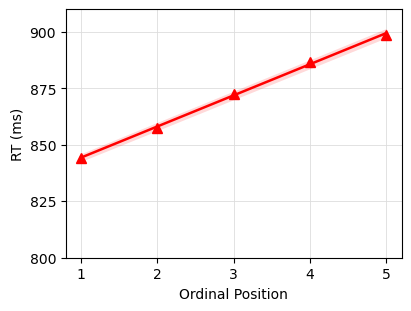

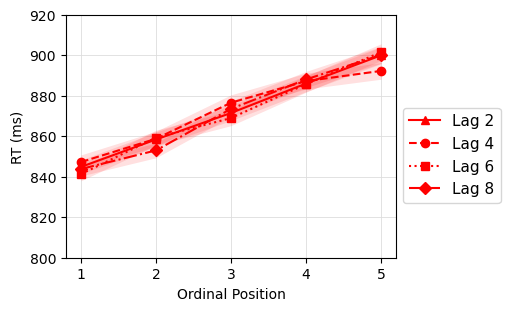

In [ ]:
def _style(ax, ylim, step=25):
    ax.set_ylim(*ylim); ax.set_yticks(np.arange(ylim[0], ylim[1] + 1, step))
    ax.grid(True, color='#dddddd', linewidth=0.6); ax.set_axisbelow(True)

def plot_ordinal(df, ylim=(800, 910), band='se', figsize=(4, 3), color='red', save_path=None):
    """Panel (b): simulated mean RT by ordinal position (collapsed across lags), linear fit, ±1 SE band."""
    pos = np.arange(1, 6)
    g = df.groupby('ordinal_position')['RT']
    m = g.mean().reindex(pos).to_numpy()
    se = (g.std(ddof=1) / np.sqrt(g.count())).reindex(pos).to_numpy()
    b, a = np.polyfit(pos, m, 1); fit = a + b * pos
    fig, ax = plt.subplots(figsize=figsize, constrained_layout=True)
    if band == 'se':
        ax.fill_between(pos, fit - se, fit + se, color=color, alpha=0.15, linewidth=0)
    ax.plot(pos, fit, color=color, linewidth=1.8)
    ax.plot(pos, m, '^', color=color, markersize=7)
    _style(ax, ylim); ax.set_xticks(pos); ax.set_xlabel('Ordinal Position'); ax.set_ylabel('RT (ms)')
    if save_path: fig.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.show()


def plot_all_lags(df, lags=LAGS, ylim=(800, 920), figsize=(5, 3), band='se', color='red',
                  legend_size=11, save_path=None):
    """Simulated mean RT by ordinal position for each lag; lag coded by marker + line style, ±1 SE band."""
    pos = np.arange(1, 6)
    style = {2: ('^', '-'), 4: ('o', '--'), 6: ('s', ':'), 8: ('D', '-.')}
    fig, ax = plt.subplots(figsize=figsize, constrained_layout=True)
    for lag in lags:
        mk, ls = style[lag]
        g = df[df['lag'] == lag].groupby('ordinal_position')['RT']
        y = g.mean().reindex(pos).to_numpy()
        se = (g.std(ddof=1) / np.sqrt(g.count())).reindex(pos).to_numpy()
        ax.plot(pos, y, marker=mk, linestyle=ls, color=color, linewidth=1.5, markersize=6)
        if band == 'se':
            ax.fill_between(pos, y - se, y + se, color=color, alpha=0.12, linewidth=0)
    ax.set_xticks(pos); ax.set_xlabel('Ordinal Position'); ax.set_ylabel('RT (ms)')
    _style(ax, ylim, step=20)
    handles = [Line2D([0], [0], color=color, marker=style[l][0], linestyle=style[l][1], linewidth=1.5,
                      markersize=6, label=f'Lag {l}') for l in lags]
    fig.legend(handles=handles, fontsize=legend_size, loc='outside right center')
    if save_path: fig.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.show()


plot_ordinal(data, save_path='cn_fig_1.png')
plot_all_lags(data, save_path='cn_fig_2.png')

In [ ]:
ETA_VALUES = np.round(np.arange(0.001, 0.0151, 0.001), 3)
K_VALUES = np.round(np.arange(3.5, 5.6, 0.25), 2)
N_SEARCH =  1000


def search_participant(seed, eta, k, lag=2):
    np.random.seed(seed)
    tr = run_cn(lag, eta, k)
    pos = [t[0] for t in tr]; rt = [t[2] for t in tr]
    return np.polyfit(pos, rt, 1)[0], 1 - np.mean([t[3] for t in tr])


def cn_search(eta_values=ETA_VALUES, k_values=K_VALUES, n=N_SEARCH, n_jobs=-1, path='cn_search.csv'):
    base = np.random.SeedSequence().entropy
    rows = []
    for cell, (eta, k) in enumerate((e, kk) for e in eta_values for kk in k_values):
        t0 = time.time()
        seeds = np.random.SeedSequence([base, cell]).generate_state(n)
        res = np.array(Parallel(n_jobs=n_jobs)(delayed(search_participant)(int(sd), eta, k) for sd in seeds), float)
        res = res[np.isfinite(res).all(1)]
        s = res[:, 0]; se = s.std(ddof=1) / np.sqrt(len(s))
        rows.append(dict(eta=eta, k=k, base_seed=str(base), cell=cell, n=len(s), slope=s.mean(), se=se, t=s.mean() / se,
                         err=res[:, 1].mean() * 100))
        pd.DataFrame(rows).to_csv(path, index=False)
        print(f"eta={eta:g} k={k:g}  slope={s.mean():.1f}  t={rows[-1]['t']:.2f}  err={rows[-1]['err']:.1f}%  ({time.time() - t0:.0f} s)")
    return pd.DataFrame(rows)


search = cn_search()

In [ ]:
def plot_t_gray(df, x_col, y_col, t_col='t', n_col='n', x_label=None, y_label=None,
                cbar_label='t', sig=0.05, err_col=None, err_max=None, vlim=5, annot_size=9,
                gray='#d4d4d2', cmap='viridis', figsize=(7.5, 6.2), save_path=None):
    """Heatmap of per-cell t (one-sample t across participants, df = n - 1). Gray: two-sided p >= sig."""
    cmap = plt.get_cmap(cmap)
    ys = np.sort(df[y_col].unique()); xs = np.sort(df[x_col].unique())
    piv = lambda c: df.pivot(index=y_col, columns=x_col, values=c).loc[ys, xs].to_numpy()
    T = piv(t_col).astype(float)
    dof = int(df[n_col].min()) - 1
    grey = ~(2 * t_dist.sf(np.abs(T), dof) < sig)
    if err_col is not None and err_max is not None:
        grey |= piv(err_col) >= err_max
    print(f'{int((~grey).sum())} coloured, {int(grey.sum())} gray of {T.size} cells')
    norm = TwoSlopeNorm(vcenter=0, vmin=-vlim, vmax=vlim)
    fig, ax = plt.subplots(figsize=figsize, constrained_layout=True)
    im = ax.imshow(T, cmap=cmap, norm=norm, origin='lower', aspect='auto')
    ax.set_xticks(range(len(xs))); ax.set_xticklabels([f'{v:g}' for v in xs], rotation=45)
    ax.set_yticks(range(len(ys))); ax.set_yticklabels([f'{v:g}' for v in ys])
    ax.set_xlabel(x_label or x_col); ax.set_ylabel(y_label or y_col)
    for i in range(len(ys)):
        for j in range(len(xs)):
            if grey[i, j]:
                ax.add_patch(plt.Rectangle((j - .5, i - .5), 1, 1, color=gray, zorder=2))
                ink = '#1a1a19'
            else:
                r_, g_, b_ = to_rgb(cmap(norm(T[i, j])))
                ink = '#1a1a19' if 0.2126 * r_ + 0.7152 * g_ + 0.0722 * b_ > 0.55 else '#fcfcfb'
            ax.text(j, i, f'{T[i, j]:.1f}', ha='center', va='center', fontsize=annot_size, color=ink, zorder=3)
    ax.set_xticks(np.arange(-.5, len(xs)), minor=True)
    ax.set_yticks(np.arange(-.5, len(ys)), minor=True)
    ax.set_axisbelow(False)
    ax.grid(which='minor', color='white', linewidth=1.5)
    ax.tick_params(which='minor', length=0)
    fig.colorbar(im, ax=ax, shrink=0.85, extend='both', label=cbar_label)
    if save_path:
        fig.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.show()

none, two-sided, m = 135 testable cells: 102 pass, 0 excluded by error, 33 not significant


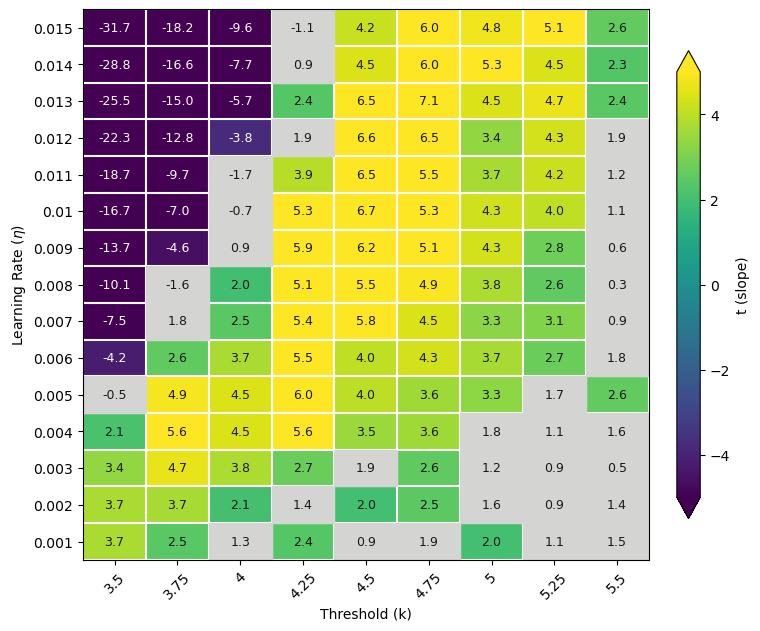

In [ ]:
plot_t_gray(search, 'k', 'eta', x_label='Threshold (k)', y_label=r'Learning Rate ($\eta$)',
            cbar_label='t (slope)', save_path='cn_t_heatmap.png')